# Meeting: the game (one submission)

**Teams.** Groups of 4, each split into two pairs. Each pair **makes** a dataset for the other pair,
and **attacks** the dataset the other pair made.

**1. Make (15 minutes).** Choose a **secret rule** on 5 features $x_1, \dots, x_5$ (each between $-3$
and $3$): the label is 1 where your formula $g(x) > 0$. The rules for rules:
- allowed: polynomials up to degree 3, products, squares, distances from a point, $\sin$ / $\cos$ of a
  feature (times a number);
- **at most 3** of the 5 features (the others are decoys);
- both labels at least 25% of the points;
- **not too easy**: if polynomial features of degree 2 already get within 10 points of your own score,
  the rule is rejected (a circle, for example, is too easy). Waves, products of three features, cubics
  are fine.

Also write your **right features**: the columns that make your rule easy. `make_game` checks the rules,
flips 5% of the labels (noise), saves a **train file** (send it to the other pair) and a secret **test
file** (keep it), and computes **your score**: the test accuracy of plain `LogisticRegression()` on your
right features. That is the target for the other pair.

**2. Attack (the rest of the time).** Find the best columns for the other pair's data: write
`features(X)`, at most 500 columns. The model is fixed: `the_model()`, scaling and then logistic
regression. Use it in your own experiments too, so that you test exactly what will be scored.

**3. ONE submission.** You submit **once**: your `features` function. The makers run
`score_submission`.

$$\text{your result} = \text{your test accuracy} - \text{the makers' test accuracy}$$

(0 means as good as the makers' own right features; above 0 is possible but rare). The higher result in
the group wins.

**One submission means you can't try things on the test set.** How will you know, before submitting,
how well your columns will do on points you have never seen?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3


def plot_boundary(model, X, y, features, title=""):
    # colour the plane by the model's probability, and draw the 0.5 boundary;
    # features: the function that turns points (x1, x2) into the model's columns
    pad = 0.3
    g1, g2 = np.meshgrid(np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, 300),
                         np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, 300))
    probs = model.predict_proba(features(np.c_[g1.ravel(), g2.ravel()]))[:, 1].reshape(g1.shape)
    plt.contourf(g1, g2, probs, levels=20, cmap="coolwarm", alpha=0.6)
    plt.contour(g1, g2, probs, levels=[0.5], colors="k", linewidths=1.5)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k", s=12)
    plt.gca().set_aspect("equal"); plt.title(title); plt.show()


N_TRAIN, N_TEST = 1000, 5000      # the size of the train file (see the teacher's note at the end)


def make_game(name, rule, right_features, seed=0):
    # Makers: make the data from your secret rule, check the rules, and compute your score.
    rng = np.random.default_rng(seed)
    X = rng.uniform(-3, 3, size=(N_TRAIN + N_TEST, 5))
    y = (rule(X) > 0).astype(int)
    if not 0.25 <= y.mean() <= 0.75:
        print(f"REJECTED: {y.mean():.0%} of the points have label 1; both labels need at least 25%.")
        return None
    used = [j for j in range(5) if np.any((rule(np.c_[X[:, :j], rng.permutation(X[:, j]), X[:, j + 1:]]) > 0) != y)]
    if len(used) > 3:
        print(f"REJECTED: your rule uses {len(used)} features; at most 3.")
        return None
    y = np.where(rng.random(len(y)) < 0.05, 1 - y, y)          # 5% noise
    df = pd.DataFrame(X, columns=[f"x{j + 1}" for j in range(5)])
    df["label"] = y
    df.iloc[:N_TRAIN].to_csv(f"game_train_{name}.csv", index=False)
    df.iloc[N_TRAIN:].to_csv(f"game_test_{name}.csv", index=False)
    model = the_model().fit(right_features(X[:N_TRAIN]), y[:N_TRAIN])
    score = round(model.score(right_features(X[N_TRAIN:]), y[N_TRAIN:]), 4)
    if score < 0.85:
        print(f"REJECTED: with your right features the test accuracy is only {score}; it must be at least 0.85.")
        return None
    poly2 = make_pipeline(PolynomialFeatures(degree=2, include_bias=False), StandardScaler(), LogisticRegression(max_iter=5000))
    easy = poly2.fit(X[:N_TRAIN], y[:N_TRAIN]).score(X[N_TRAIN:], y[N_TRAIN:])
    if easy > score - 0.10:
        print(f"REJECTED: too easy. Degree-2 polynomial features already get {easy:.3f}, your score is {score}. "
              "Make the rule more complex (waves, products of three features, cubics ...).")
        return None
    print(f"OK: saved game_train_{name}.csv (send it) and game_test_{name}.csv (keep it).")
    print(f"Your rule uses x{', x'.join(str(j + 1) for j in used)}.  YOUR SCORE (the target): {score}")
    return score


def the_model():
    # the model of the game, for everyone: scale the columns, then logistic regression
    return make_pipeline(StandardScaler(), LogisticRegression(C=1e4, max_iter=5000))


def score_submission(features, name, makers_score):
    # Makers: run this ONCE, on the other pair's features function.
    train, test = pd.read_csv(f"game_train_{name}.csv"), pd.read_csv(f"game_test_{name}.csv")
    cols = [f"x{j + 1}" for j in range(5)]
    F_train, F_test = features(train[cols].values), features(test[cols].values)
    if F_train.shape[1] > 500:
        print(f"{F_train.shape[1]} columns: at most 500 are allowed.")
        return None
    model = the_model().fit(F_train, train["label"])
    train_acc, test_acc = model.score(F_train, train["label"]), model.score(F_test, test["label"])
    print(f"{F_train.shape[1]} columns: training accuracy {train_acc:.4f}, TEST accuracy {test_acc:.4f}")
    print(f"the makers' score {makers_score}:  RESULT {test_acc - makers_score:+.4f}")
    return test_acc - makers_score


def show_pairs(df):
    # Attackers: every pair of features, coloured by the label
    cols = [f"x{j + 1}" for j in range(5)]
    sample = df.sample(min(len(df), 1500), random_state=0)
    fig, axes = plt.subplots(2, 5, figsize=(16, 6.5))
    pairs = [(a, b) for i, a in enumerate(cols) for b in cols[i + 1:]]
    for ax, (a, b) in zip(axes.ravel(), pairs):
        ax.scatter(sample[a], sample[b], c=sample["label"], cmap="coolwarm", s=4)
        ax.set_xlabel(a); ax.set_ylabel(b)
    plt.tight_layout(); plt.show()

## 1. Makers

**First, in your group of 4: decide which pair is `team_a` and which is `team_b`.** Write it in the
cell below: your own name first, the other pair's second. (The two pairs fill in the same two names,
swapped.)

Then your rule and your right features. (The rule below is an example of the form; change it!)

In [2]:
our_team_name = "team_1"        # <- your pair: "team_a" or "team_b"
other_team_name = "team_a"      # <- the other pair

In [ ]:
x1 = lambda X: X[:, 0]
x2 = lambda X: X[:, 2]
x3 = lambda X: X[:, 4]

rule = lambda X: np.sin(4 * (x1(X)) * (x3(X))) + np.cos(4 * (x2(X)))*x2(X) + (x3(X)**(3))*np.sin(x1(X)) + x1(X)*x2(X)*x3(X) + (x1(X) + 3)
right_features = lambda X: np.c_[np.sin(4 * (x1(X)) * (x3(X))), np.cos(4 * (x2(X)))*x2(X), (x3(X)**(3))*np.sin(x1(X)), x1(X)*x2(X)*x3(X), (x1(X) + 3)]
makers_score = make_game(our_team_name, rule, right_features)

OK: saved game_train_team_1.csv (send it) and game_test_team_1.csv (keep it).
Your rule uses x1, x3, x5.  YOUR SCORE (the target): 0.9064


## 2. Attackers

Load the other pair's train file. Look, think, try. Remember: **one** submission.

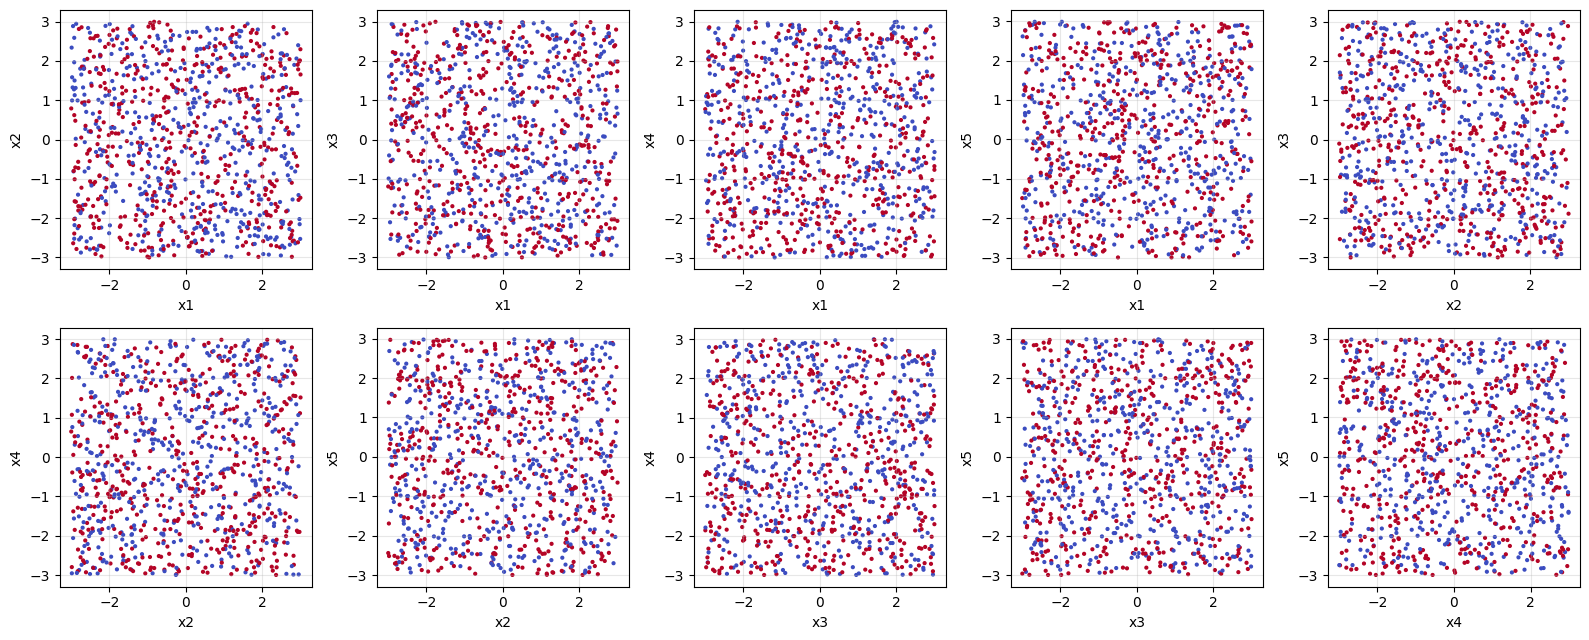

In [4]:
game = pd.read_csv(f"game_train_{other_team_name}.csv")                       # <- the other pair's file
X_all, y_all = game[["x1", "x2", "x3", "x4", "x5"]].values, game["label"].values
show_pairs(game)

In [ ]:
from itertools import combinations
import numpy as np
import plotly.graph_objects as go

def plot_label_vs_triples(X, y, max_points=5000, seed=0):
    X = np.asarray(X)
    y = np.asarray(y).ravel()
    if len(X) > max_points:
        idx = np.random.default_rng(seed).choice(len(X), max_points, replace=False)
        X, y = X[idx], y[idx]

    combos = list(combinations(range(X.shape[1]), 3))   # 10 combos for 5 cols
    colors = {0: "royalblue", 1: "crimson"}

    fig = go.Figure()
    for k, (a, b, c) in enumerate(combos):
        for lbl in (0, 1):
            m = y == lbl
            fig.add_trace(go.Scatter3d(
                x=X[m, a], y=X[m, b], z=X[m, c],
                mode="markers", name=f"label {lbl}",
                marker=dict(size=3, opacity=0.5, color=colors[lbl]),
                visible=(k == 0),
            ))

    buttons = []
    for k, (a, b, c) in enumerate(combos):
        vis = [j // 2 == k for j in range(2 * len(combos))]
        buttons.append(dict(
            label=f"cols ({a}, {b}, {c})",
            method="update",
            args=[{"visible": vis},
                  {"scene.xaxis.title": f"col {a}",
                   "scene.yaxis.title": f"col {b}",
                   "scene.zaxis.title": f"col {c}"}],
        ))

    a, b, c = combos[0]
    fig.update_layout(
        height=800,
        scene=dict(xaxis_title=f"col {a}", yaxis_title=f"col {b}", zaxis_title=f"col {c}"),
        updatemenus=[dict(buttons=buttons, direction="down", x=0.0, y=1.1)],
    )
    fig.show()

plot_label_vs_triples(X_all, y_all)   # X: (N, 5), y: (N, 1)

In [8]:
def features(X):
    # X: the 5 columns. Return your columns (at most 500).
    x0,x1,x2,x3,x4 = X[:,0], X[:,1], X[:,2], X[:,3], X[:,4]
    return np.c_[x0,x2,np.abs(x0+x4),x4**2*x0, x4**2,np.sin(x0*x4),x4**3, x4*x0,x0**2*x4, x2*x0, x2*x4*x0]

In [6]:
model = the_model()     # the model of the game: use it in your experiments

possible_functions = [
    lambda x, k: np.sin(k * x),
    lambda x, k: np.cos(k * x),
    lambda x, k: k * x
]

X_tr, X_te, y_tr, y_te = (None, None, None, None)

best_columns = []
best_score = -1
best_coeff = None
best_intercept = None
counter = 0
for i in [0]:
    for j in [1]:
        for k in [3]:
            arr = []
            X_tr, X_te, y_tr, y_te = train_test_split(X_all, y_all, test_size=0.2, random_state=0)
            for a in range(0, 4):
                for b in range(0, 4):
                    for c in range(0, 4):
                        for d in possible_functions:
                            for e in possible_functions:
                                for f in possible_functions:
                                    for k1 in np.linspace(1, 4, 3):
                                        for k2 in np.linspace(1, 4, 3):
                                            for k3 in np.linspace(1, 4, 3):
                                                counter += 1
                                                print(counter/((4*3*3)**3))
                                                arr.append((d(X_tr[:, i], k1)**a)*(e(X_tr[:, j], k2)**b)*(f(X_tr[:, k], k3)**c))
            testing_features = np.column_stack(arr)
            model.fit(testing_features, y_tr)
            coef = model[-1].coef_
            inter = model[-1].intercept_

2.143347050754458e-05
4.286694101508916e-05
6.430041152263375e-05
8.573388203017832e-05
0.0001071673525377229
0.0001286008230452675
0.00015003429355281208
0.00017146776406035664
0.00019290123456790122
0.0002143347050754458
0.0002357681755829904
0.000257201646090535
0.00027863511659807956
0.00030006858710562417
0.0003215020576131687
0.0003429355281207133
0.0003643689986282579
0.00038580246913580245
0.00040723593964334706
0.0004286694101508916
0.0004501028806584362
0.0004715363511659808
0.0004929698216735253
0.00051440329218107
0.0005358367626886146
0.0005572702331961591
0.0005787037037037037
0.0006001371742112483
0.0006215706447187929
0.0006430041152263374
0.000664437585733882
0.0006858710562414266
0.0007073045267489712
0.0007287379972565158
0.0007501714677640603
0.0007716049382716049
0.0007930384087791496
0.0008144718792866941
0.0008359053497942387
0.0008573388203017832
0.0008787722908093279
0.0009002057613168725
0.000921639231824417
0.0009430727023319616
0.0009645061728395061
0.000985

In [7]:
results = []
result = ""
converter = ["np.sin", "np.cos", ""]
counter = 0
for a in range(0, 4):
    for b in range(0, 4):
        for c in range(0, 4):
            for d in range(len(possible_functions)):
                for e in range(len(possible_functions)):
                    for f in range(len(possible_functions)):
                        for k1 in np.linspace(1, 4, 3):
                            for k2 in np.linspace(1, 4, 3):
                                for k3 in np.linspace(1, 4, 3):
                                    if (abs(coef[0][counter]) > 0.5):
                                        temp = []
                                        if (a != 0):
                                            temp.append(f"({converter[d]}({k1}*X[:, 0])**{a})")
                                        if (b != 0):
                                            temp.append(f"({converter[e]}({k2}*X[:, 1])**{b})")
                                        if (c != 0):
                                            temp.append(f"({converter[f]}({k3}*X[:, 3])**{c})")
                                        if ((not (a == 0 and b == 0 and c == 0)) and "*".join(temp) not in results):
                                            results.append(("*".join(temp)))
                                    counter += 1

print(", ".join(results))

(np.cos(4.0*X[:, 1])**1)*(np.cos(4.0*X[:, 3])**1), (np.cos(4.0*X[:, 1])**1)*(np.cos(4.0*X[:, 3])**3), (np.cos(4.0*X[:, 1])**3)*(np.cos(4.0*X[:, 3])**3), (np.cos(1.0*X[:, 0])**1)*(np.cos(4.0*X[:, 3])**2), (np.cos(2.5*X[:, 0])**1)*(np.sin(2.5*X[:, 3])**3), (np.sin(2.5*X[:, 0])**1)*(np.sin(1.0*X[:, 1])**1)*(np.sin(2.5*X[:, 3])**1), (np.sin(4.0*X[:, 0])**1)*(np.sin(4.0*X[:, 1])**1)*(np.sin(4.0*X[:, 3])**1), (np.sin(1.0*X[:, 0])**1)*(np.sin(2.5*X[:, 1])**1)*(np.cos(1.0*X[:, 3])**1), (np.sin(4.0*X[:, 0])**1)*(np.sin(1.0*X[:, 1])**1)*(np.cos(1.0*X[:, 3])**1), (np.sin(1.0*X[:, 0])**1)*(np.cos(1.0*X[:, 1])**1)*(np.sin(2.5*X[:, 3])**1), (np.sin(1.0*X[:, 0])**1)*(np.cos(1.0*X[:, 1])**1)*(np.sin(4.0*X[:, 3])**1), (np.sin(2.5*X[:, 0])**1)*(np.cos(1.0*X[:, 1])**1)*(np.sin(2.5*X[:, 3])**1), (np.sin(2.5*X[:, 0])**1)*(np.cos(1.0*X[:, 1])**1)*(np.sin(4.0*X[:, 3])**1), (np.sin(2.5*X[:, 0])**1)*(np.cos(2.5*X[:, 1])**1)*(np.sin(4.0*X[:, 3])**1), (np.sin(2.5*X[:, 0])**1)*(np.cos(4.0*X[:, 1])**1)*(np.sin(2.5

## 3. The submission

**Makers:** paste the other pair's `features` function above this line, and run **once**.

In [9]:
result = score_submission(features, our_team_name, makers_score)

11 columns: training accuracy 0.8540, TEST accuracy 0.8402
the makers' score 0.9064:  RESULT -0.0662


### ✅ Solution

*Together in class, after you try.*